# 14 Regresi dan Ordinal

Target berupa angka atau tingkatan. Contoh: rating 1-5 ulasan Tokopedia.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Memprediksi nilai atau tingkatan |
| **Unit prediksi** | Satu ulasan mendapat nilai 1 sampai 5 |
| **Metrik** | RMSE, MAE, dan QWK |
| **Masalah terbesar** | Rating sangat timpang (bintang 5 sebanyak 73,4%) dan isi ulasan sering tidak sesuai bintangnya. |
| **Data contoh** | 5.000 ulasan Tokopedia dari 1.396 produk |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** target berupa angka kontinu (RMSE, MAE) atau tingkatan berurutan (QWK), misalnya rating,
skor kepuasan, atau tingkat urgensi keluhan.

**Yang perlu diganti kalau datanya beda:**
- `load_data`, `TEXT_COL`, `TARGET_COL`.
- Metrik utama di bagian 6. Kalau kontinu, bagian cut point di bagian 9 dilewati.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya TF-IDF, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
HOLDOUT_SHARE = 0.2
TEXT_COL, TARGET_COL = "text", "rating"

SETTINGS = {
    "cepat": {"folds": 3, "epochs": 3, "model_runs": [("indobert", SEED)]},
    "penuh": {
        "folds": 5,
        "epochs": 4,
        "model_runs": [("indobert", SEED), ("indobertweet", SEED), ("indobert", SEED + 1)],
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'folds': 5, 'epochs': 4, 'model_runs': [('indobert', 42), ('indobertweet', 42), ('indobert', 43)]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Metrik, interval noise, dan pencatat hasil.** Metrik diuji dulu pada contoh yang jawabannya
dihitung manual. `record` mencatat skor OOF dan skor holdout untuk tiap pendekatan.

In [6]:
from sklearn.metrics import f1_score  # noqa: E402
from sklearn.model_selection import StratifiedGroupKFold  # noqa: E402


def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


assert abs(macro_f1([0, 0, 1, 1], [0, 1, 1, 1]) - (2 / 3 + 0.8) / 2) < 1e-9


def bootstrap_interval(y_true, y_pred, score_fn=macro_f1, n_boot: int = 300) -> str:
    """Interval 95%. Selisih di dalam interval ini belum tentu perbaikan nyata."""
    rng = np.random.default_rng(SEED)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(y_true), len(y_true))
        scores.append(score_fn(y_true[pick], y_pred[pick]))
    return f"{np.percentile(scores, 2.5):.3f}-{np.percentile(scores, 97.5):.3f}"


def make_folds(target, groups, n_folds: int) -> np.ndarray:
    """StratifiedGroupKFold: duplikat tidak lintas fold, proporsi kelas terjaga."""
    splitter = StratifiedGroupKFold(n_folds, shuffle=True, random_state=SEED)
    folds = np.zeros(len(target), dtype=int)
    for fold, (_, val_idx) in enumerate(splitter.split(np.zeros(len(target)), target, groups)):
        folds[val_idx] = fold
    return folds


results: list[dict] = []


def record(name: str, oof_pred, holdout_pred, score_fn=macro_f1) -> None:
    """Catat skor OOF dan holdout. Holdout hanya untuk laporan, bukan untuk memilih model."""
    results.append(
        {
            "model": name,
            "oof": round(score_fn(y, oof_pred), 4),
            "oof_ci95": bootstrap_interval(y, oof_pred, score_fn),
            "holdout": round(score_fn(y_holdout, holdout_pred), 4),
        }
    )
    print(results[-1])

**Model dengan cross-validation.** `cv_tfidf` adalah baseline word dan char TF-IDF + regresi
logistik, sedangkan `cv_transformer` melatih tiap kombinasi model dan seed di semua fold. Hasilnya
probabilitas OOF dan rata-rata probabilitas holdout.

In [7]:
from scipy.sparse import hstack  # noqa: E402
from sklearn.multiclass import OneVsRestClassifier  # noqa: E402


def cv_tfidf(train_texts, target, holdout_texts, folds, multilabel=False):
    """Baseline TF-IDF. Vektorisasi difit di dalam fold supaya tidak bocor."""
    target = np.asarray(target)
    shape = target.shape[1] if multilabel else int(target.max()) + 1
    oof = np.zeros((len(target), shape))
    holdout = np.zeros((len(holdout_texts), shape))
    train_texts = pd.Series(list(train_texts))
    holdout_series = pd.Series(list(holdout_texts))
    for fold in np.unique(folds):
        fit, val = folds != fold, folds == fold
        word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
        char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)
        x_fit = hstack([word.fit_transform(train_texts[fit]), char.fit_transform(train_texts[fit])])
        base = LogisticRegression(C=3.0, max_iter=2000, class_weight="balanced")
        model = OneVsRestClassifier(base) if multilabel else base
        model.fit(x_fit.tocsr(), target[fit])
        for mask_texts, store, where in (
            (train_texts[val], oof, val),
            (holdout_series, holdout, None),
        ):
            x_pred = hstack([word.transform(mask_texts), char.transform(mask_texts)]).tocsr()
            probs = model.predict_proba(x_pred)
            if where is None:
                store += probs / len(np.unique(folds))
            else:
                store[where] = probs
    return oof, holdout


def cv_transformer(
    train_texts,
    target,
    holdout_texts,
    folds,
    model_runs,
    epochs,
    problem="ce",
    balanced=True,
    max_len=128,
):
    """Latih tiap (model, seed) di semua fold, lalu rata-ratakan probabilitasnya."""
    target = np.asarray(target)
    train_texts = np.array(list(train_texts), dtype=object)
    holdout_texts = list(holdout_texts)
    n_out = (
        target.shape[1] if problem == "bce" else (1 if problem == "mse" else int(target.max()) + 1)
    )
    oof = np.zeros((len(target), n_out))
    holdout = np.zeros((len(holdout_texts), n_out))
    n_folds = len(np.unique(folds))
    for model_name, seed in model_runs:
        for fold in range(n_folds):
            fit, val = folds != fold, folds == fold
            weights = None
            if problem == "ce" and balanced:
                weights = len(target[fit]) / (n_out * np.bincount(target[fit], minlength=n_out))
            elif problem == "bce" and balanced:
                positives = np.maximum(target[fit].sum(0), 1)
                weights = np.clip((len(target[fit]) - positives) / positives, 1, 20)
            pred_val, pred_hold = train_predict(
                model_name,
                train_texts[fit].tolist(),
                target[fit],
                [train_texts[val].tolist(), holdout_texts],
                problem=problem,
                num_labels=n_out if problem != "bce" else None,
                class_weights=weights,
                epochs=epochs,
                seed=seed + fold,
                max_len=max_len,
            )
            oof[val] += pred_val.reshape(val.sum(), -1) / len(model_runs)
            holdout += pred_hold.reshape(len(holdout_texts), -1) / (n_folds * len(model_runs))
    return oof, holdout

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [8]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [9]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat data dan sisihkan holdout. Produk yang sama dijadikan satu grup, supaya ulasan satu produk tidak
lintas fold.

In [10]:
from sklearn.metrics import cohen_kappa_score, mean_absolute_error, mean_squared_error  # noqa: E402
from sklearn.model_selection import GroupShuffleSplit  # noqa: E402


def load_data() -> pd.DataFrame:
    frame = pd.read_csv(find_file("tokopedia-product-reviews-2019.csv")).dropna(
        subset=[TEXT_COL, TARGET_COL]
    )
    return frame.sample(n=min(N_ROWS, len(frame)), random_state=SEED).reset_index(drop=True)


data = load_data()
splitter = GroupShuffleSplit(1, test_size=HOLDOUT_SHARE, random_state=SEED)
fit_idx, hold_idx = next(splitter.split(data, groups=data["product_id"]))
train, holdout = (
    data.iloc[fit_idx].reset_index(drop=True),
    data.iloc[hold_idx].reset_index(drop=True),
)
print(f"latih={len(train)} | holdout={len(holdout)} | produk unik={data['product_id'].nunique()}")
text_profile(train[TEXT_COL])

latih=3993 | holdout=1007 | produk unik=1396


baris                3993.0
kosong                  0.0
duplikat_persis_%       1.6
kata_median             6.0
kata_p95               19.0
kata_maks             208.0
ada_url_%               0.0
ada_emoji_%             3.3
dtype: float64

Sebaran target dan hubungan panjang teks dengan rating.

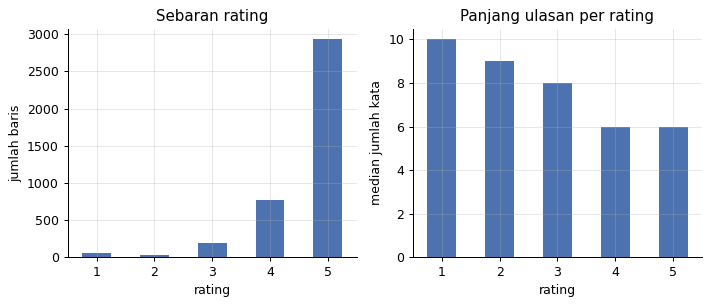

proporsi rating: {1: 0.015, 2: 0.009, 3: 0.049, 4: 0.194, 5: 0.734}


In [11]:
fig, axes = plt.subplots(1, 2)
train[TARGET_COL].value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title="Sebaran rating", xlabel="rating", ylabel="jumlah baris")
axes[0].tick_params(axis="x", rotation=0)
train.groupby(TARGET_COL)[TEXT_COL].apply(lambda s: s.str.split().str.len().median()).plot.bar(
    ax=axes[1], color="#4C72B0"
)
axes[1].set(title="Panjang ulasan per rating", xlabel="rating", ylabel="median jumlah kata")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
print(
    "proporsi rating:",
    train[TARGET_COL].value_counts(normalize=True).sort_index().round(3).to_dict(),
)

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Satu produk muncul di banyak ulasan | Grup validasi memakai id produk dan near-duplicate |
| Median hanya 6 kata | Pembersihan ringan, dan tanda baca tetap ada |
| Bintang 1 dan 2 masing-masing di bawah 2% | Cut point difit nested untuk QWK |

## 5. Preprocessing

Pembersihan ringan. Grup untuk validasi memakai id produk sekaligus near-duplicate, karena banyak ulasan
pendek yang sama persis.

In [12]:
train["clean"] = train[TEXT_COL].map(clean_text)
holdout["clean"] = holdout[TEXT_COL].map(clean_text)
near_dup = near_duplicate_groups(train["clean"].tolist())
train["group"] = pd.factorize(
    train["product_id"].astype(str) + "_" + pd.Series(near_dup).astype(str)
)[0]
y = train[TARGET_COL].to_numpy()
y_holdout = holdout[TARGET_COL].to_numpy()
print(f"grup near-duplicate: {len(set(near_dup))} dari {len(train)} baris")

grup near-duplicate: 3583 dari 3993 baris


## 6. Validasi

Skema `StratifiedGroupKFold`. Ada tiga metrik: RMSE dan MAE untuk nilai kontinu, dan QWK untuk tingkatan.
QWK butuh prediksi bulat, jadi cut point ikut menentukan skornya.

In [13]:
def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def qwk(y_true, y_pred) -> float:
    return float(
        cohen_kappa_score(y_true, np.clip(np.rint(y_pred), 1, 5).astype(int), weights="quadratic")
    )


assert abs(rmse([1, 3], [1, 1]) - np.sqrt(2)) < 1e-9
assert qwk([1, 2, 3], [1, 2, 3]) == 1.0
folds = make_folds(y, train["group"], SETTINGS["folds"])
print(pd.crosstab(folds, y))


def record_reg(name: str, oof_pred, holdout_pred) -> None:
    results.append(
        {
            "model": name,
            "rmse_oof": round(rmse(y, oof_pred), 4),
            "mae_oof": round(mean_absolute_error(y, oof_pred), 4),
            "qwk_oof": round(qwk(y, oof_pred), 4),
            "qwk_ci95": bootstrap_interval(y, oof_pred, qwk),
            "rmse_holdout": round(rmse(y_holdout, holdout_pred), 4),
            "qwk_holdout": round(qwk(y_holdout, holdout_pred), 4),
        }
    )
    print(results[-1])

col_0   1   2   3    4    5
row_0                      
0      11   7  43  166  572
1      10   7  43  158  580
2      11   4  34  151  600
3      13  10  34  146  597
4      13   8  42  152  581


## 7. Baseline

Tebak rata-rata, lalu TF-IDF + Ridge.

In [14]:
from sklearn.linear_model import Ridge  # noqa: E402

record_reg("rata_rata", np.full(len(y), y.mean()), np.full(len(y_holdout), y.mean()))

oof_ridge, hold_ridge = np.zeros(len(y)), np.zeros(len(y_holdout))
for fold in np.unique(folds):
    fit, val = folds != fold, folds == fold
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    model = Ridge(alpha=1.0).fit(vectorizer.fit_transform(train.loc[fit, "clean"]), y[fit])
    oof_ridge[val] = model.predict(vectorizer.transform(train.loc[val, "clean"]))
    hold_ridge += model.predict(vectorizer.transform(holdout["clean"])) / SETTINGS["folds"]
record_reg("tfidf_ridge", oof_ridge, hold_ridge)

{'model': 'rata_rata', 'rmse_oof': 0.7493, 'mae_oof': 0.5531, 'qwk_oof': 0.0, 'qwk_ci95': '0.000-0.000', 'rmse_holdout': 0.6609, 'qwk_holdout': 0.0}


{'model': 'tfidf_ridge', 'rmse_oof': 0.6555, 'mae_oof': 0.4621, 'qwk_oof': 0.3926, 'qwk_ci95': '0.362-0.425', 'rmse_holdout': 0.5935, 'qwk_holdout': 0.3596}


## 8. Model Utama

Transformer dengan satu keluaran dan loss MSE. Target distandarkan dulu, supaya loss tidak terlalu besar
di awal training.

In [15]:
mean_y, std_y = y.mean(), y.std()
with stage("transformer"):
    if USE_PRETRAINED:
        oof_scaled, hold_scaled = cv_transformer(
            train["clean"],
            (y - mean_y) / std_y,
            holdout["clean"],
            folds,
            SETTINGS["model_runs"],
            SETTINGS["epochs"],
            problem="mse",
        )
        oof_main = oof_scaled[:, 0] * std_y + mean_y
        hold_main = hold_scaled[:, 0] * std_y + mean_y
    else:
        oof_main, hold_main = oof_ridge, hold_ridge
record_reg("model_utama", oof_main, hold_main)

[waktu] transformer: 1439 detik


{'model': 'model_utama', 'rmse_oof': 0.568, 'mae_oof': 0.3793, 'qwk_oof': 0.6047, 'qwk_ci95': '0.570-0.639', 'rmse_holdout': 0.5136, 'qwk_holdout': 0.5464}


## 9. Post-processing

**Cut point untuk QWK.** Membulatkan langsung biasanya rugi, karena prediksi regresi menumpuk di tengah.
Batas antar rating dicari untuk memaksimalkan QWK. Skor OOF dihitung nested.

In [16]:
def apply_cuts(scores: np.ndarray, cuts: np.ndarray) -> np.ndarray:
    return np.digitize(scores, np.sort(cuts)) + 1


def fit_cuts(scores: np.ndarray, target: np.ndarray) -> np.ndarray:
    """Coordinate ascent pada empat batas."""
    cuts = np.array([1.5, 2.5, 3.5, 4.5])
    grid = np.quantile(scores, np.linspace(0.005, 0.995, 80))
    for _ in range(3):
        for i in range(len(cuts)):
            values = []
            for candidate in grid:
                trial = cuts.copy()
                trial[i] = candidate
                values.append(
                    cohen_kappa_score(target, apply_cuts(scores, trial), weights="quadratic")
                )
            cuts[i] = grid[int(np.argmax(values))]
    return np.sort(cuts)


oof_cut = np.zeros(len(y))
with stage("cut_point"):
    for fold in np.unique(folds):
        fit = folds != fold
        oof_cut[~fit] = apply_cuts(oof_main[~fit], fit_cuts(oof_main[fit], y[fit]))
    cuts = fit_cuts(oof_main, y)
hold_cut = apply_cuts(hold_main, cuts)
record_reg("model_utama_plus_cut_point", oof_cut, hold_cut)
print("cut point:", cuts.round(2).tolist())

[waktu] cut_point: 15 detik


{'model': 'model_utama_plus_cut_point', 'rmse_oof': 0.6535, 'mae_oof': 0.3188, 'qwk_oof': 0.6354, 'qwk_ci95': '0.598-0.670', 'rmse_holdout': 0.5937, 'qwk_holdout': 0.5815}
cut point: [2.29, 3.37, 3.92, 4.51]


## 10. Post-analysis

**Tabel perbandingan.**

In [17]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,rmse_oof,mae_oof,qwk_oof,qwk_ci95,rmse_holdout,qwk_holdout
0,rata_rata,0.7493,0.5531,0.0000,0.000-0.000,0.6609,0.0000
1,tfidf_ridge,0.6555,0.4621,0.3926,0.362-0.425,0.5935,0.3596
2,model_utama,0.5680,0.3793,0.6047,0.570-0.639,0.5136,0.5464
3,model_utama_plus_cut_point,0.6535,0.3188,0.6354,0.598-0.670,0.5937,0.5815


**Prediksi dibanding nilai asli.** Lihat apakah prediksi menumpuk di rating mayoritas.

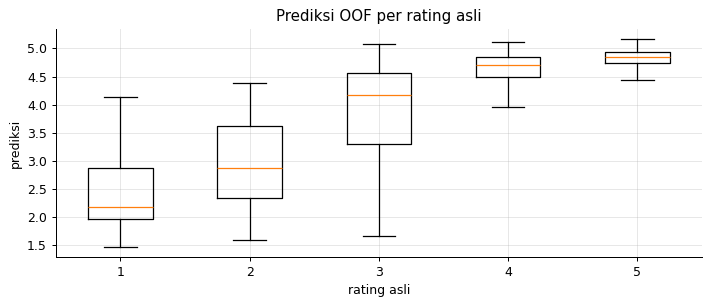

In [18]:
fig, ax = plt.subplots()
ax.boxplot([oof_main[y == r] for r in range(1, 6)], labels=range(1, 6), showfliers=False)
ax.set(title="Prediksi OOF per rating asli", xlabel="rating asli", ylabel="prediksi")
plt.tight_layout()
plt.show()

**Confusion matrix** setelah cut point.

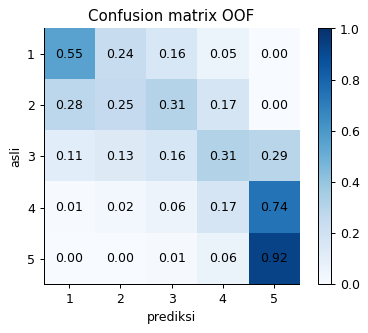

In [19]:
plot_confusion(y, oof_cut.astype(int), [1, 2, 3, 4, 5], "Confusion matrix OOF")

**Salah paling jauh.** Biasanya kelihatan ulasan yang isinya tidak sesuai rating.

In [20]:
errors = train.assign(prediksi=oof_main.round(2), selisih=np.abs(oof_main - y).round(2))
errors.sort_values("selisih", ascending=False)[["clean", TARGET_COL, "prediksi"]].head(8)

,clean,rating,prediksi
1853,"setelah 3 hari jam nya rusak...terkadang dia jalan, terkadang mati sendiri...tolong ba...",5,1.65
3205,hanya ini yg sampai.....,1,4.30
23,bad service! smoga lebih menghargai costomer,1,4.14
246,kurang bagus. kaya bekas. udah jelek. tp isi full,5,1.94
1634,parah si. itu yng ngasi bintang rendah tangannya lembek mungkin gabisa narik agak kuat...,5,1.96
185,earphone nya sih dateng tapi ngga sama kabelnya sebelum di packing di cek dulu ya teri...,1,3.98
1845,barang kosong..tp refun udah diterima...,5,2.06
3952,payah&#39;.................................,1,3.84


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [21]:
pd.DataFrame(
    {"id": holdout.index, "rating": hold_cut.astype(int), "skor": hold_main.round(3)}
).to_csv(RESULT_DIR / "submission.csv", index=False)
pd.DataFrame({"skor": oof_main, "fold": folds, "y": y}).to_csv(RESULT_DIR / "oof.csv", index=False)
run_summary(
    "regresi_ordinal",
    len(data),
    {
        r["model"]: {
            "qwk_oof": r["qwk_oof"],
            "qwk_holdout": r["qwk_holdout"],
            "rmse_holdout": r["rmse_holdout"],
        }
        for r in results
    },
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=regresi_ordinal mode=penuh n_rows=5000 total_detik=1478 gpu=True
{
 "rata_rata": {
  "qwk_oof": 0.0,
  "qwk_holdout": 0.0,
  "rmse_holdout": 0.6609
 },
 "tfidf_ridge": {
  "qwk_oof": 0.3926,
  "qwk_holdout": 0.3596,
  "rmse_holdout": 0.5935
 },
 "model_utama": {
  "qwk_oof": 0.6047,
  "qwk_holdout": 0.5464,
  "rmse_holdout": 0.5136
 },
 "model_utama_plus_cut_point": {
  "qwk_oof": 0.6354,
  "qwk_holdout": 0.5815,
  "rmse_holdout": 0.5937
 }
}


**Poin untuk presentasi**

- QWK OOF naik dari TF-IDF 0,3926 ke model utama 0,6047, lalu 0,6354 dengan cut point. Holdout 0,5815.
- **Cut point bergantung pada metrik.** QWK dan MAE membaik, tapi RMSE memburuk (0,568 ke 0,6535). Kalau metriknya RMSE, jangan dibulatkan.
- Kesalahan terbesar berasal dari label berisik, misalnya ulasan `kurang bagus. kaya bekas` diberi bintang 5.